In [1]:
#1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor

In [2]:
#2
from google.colab import drive
drive.mount('/content/drive')

# https://datos-bancomundial-org.translate.goog/indicador/SP.DYN.CBRT.IN?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=tc
ARCHIVO = "/content/drive/Othercomputers/Mi_portátil/UAI/UPSO/2 Python Avanzada/Proyecto2_Regresion/data/API_SP.DYN.CBRT.IN_DS2_es_csv_v2_12313.csv"

# skiprows=4 salta las 4 primeras líneas del archivo, que son información del Banco Mundial
df = pd.read_csv(ARCHIVO, skiprows=4, encoding="utf-8-sig")
df.head()

Mounted at /content/drive


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Tasa de natalidad, bruta (por cada 1.000 perso...",SP.DYN.CBRT.IN,32.043000,31.225000,30.386000,29.635000,28.846000,28.240000,...,11.477000,10.807000,10.842000,9.688000,9.461000,8.527000,7.973000,7.593000,NaN,NaN
1,NaN,AFE,"Tasa de natalidad, bruta (por cada 1.000 perso...",SP.DYN.CBRT.IN,47.710772,47.731227,47.790919,47.831722,47.831555,47.833772,...,34.813992,34.583807,34.335881,34.010653,33.681336,33.320606,32.955454,32.584115,NaN,NaN
2,Afganistán,AFG,"Tasa de natalidad, bruta (por cada 1.000 perso...",SP.DYN.CBRT.IN,50.516000,50.566000,50.666000,50.787000,50.852000,50.889000,...,38.171000,37.624000,37.138000,36.601000,36.342000,36.045000,35.437000,35.007000,NaN,NaN
3,NaN,AFW,"Tasa de natalidad, bruta (por cada 1.000 perso...",SP.DYN.CBRT.IN,47.520065,47.581875,47.653163,47.624643,47.627569,47.605143,...,36.993349,36.083913,35.213345,34.450875,34.133090,33.781890,33.484381,33.123823,NaN,NaN
4,Angola,AGO,"Tasa de natalidad, bruta (por cada 1.000 perso...",SP.DYN.CBRT.IN,51.615000,52.046000,52.226000,52.347000,52.410000,52.413000,...,40.595000,40.057000,39.539000,39.127000,38.670000,38.102000,37.588000,37.158000,NaN,NaN


In [19]:
# contar filas con NaN
df[["Country Name", "1960", "1980", "2000", "2024"]].isna().any(axis=1).sum()


np.int64(4)

In [20]:
# Cant NaN x col
df[["Country Name", "1960", "1980", "2000", "2024"]].isna().sum()

,0
Country Name,2
1960,2
1980,2
2000,1
2024,1


In [5]:
# Muestra las filas que tienen NaN
df[df[["Country Name", "1960", "1980", "2000", "2024"]].isna().any(axis=1)][["Country Name", "1960", "1980", "2000", "2024"]]


,Country Name,1960,1980,2000,2024
1,NaN,47.710772,46.688827,41.006958,32.584115
3,NaN,47.520065,48.001958,43.361734,33.123823
110,No clasificado,NaN,NaN,NaN,NaN
196,Ribera Occidental y Gaza,NaN,NaN,40.900000,26.465000


In [6]:
datos = df[["Country Name", "1960", "1980", "2000", "2024"]].dropna()
datos.columns = ["pais", "nat_1960", "nat_1980", "nat_2000", "nat_2024"]

print("Cantidad de filas:", len(datos))
datos.sort_values(by='nat_2024', ascending=False).head(10)

Cantidad de filas: 262


,pais,nat_1960,nat_1980,nat_2000,nat_2024
34,República Centroafricana,43.533,45.119,42.058,46.193
229,Chad,45.902,49.518,51.589,43.264
213,República Federal de Somalia,46.757,47.449,50.443,42.346
173,Níger,57.613,56.540,53.390,41.420
43,"Congo, República Democrática del",47.063,46.094,45.298,40.885
158,Malí,50.784,50.571,47.091,39.532
4,Angola,51.615,49.154,46.853,37.158
165,Mozambique,48.260,52.967,43.583,37.028
2,Afganistán,50.516,53.452,51.491,35.007
246,Tanzanía,48.970,48.312,41.528,34.801


In [7]:
# Resumen estadístico de cada variable
datos.describe().round(2)

,nat_1960,nat_1980,nat_2000,nat_2024
count,262.00,262.00,262.00,262.00
mean,37.99,31.65,24.12,17.38
std,11.48,12.60,11.60,9.44
min,13.40,11.10,7.82,4.20
25%,26.91,19.81,14.40,9.71
50%,42.56,31.67,21.85,14.56
75%,47.38,43.37,32.15,23.73
max,57.61,56.54,53.39,46.19


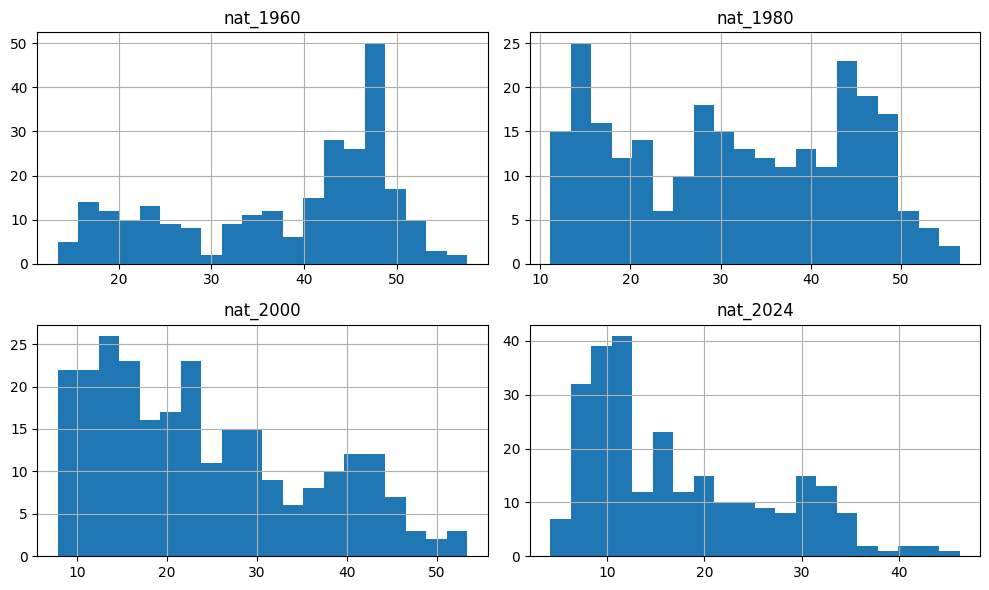

In [8]:
datos[["nat_1960", "nat_1980", "nat_2000", "nat_2024"]].hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.show()

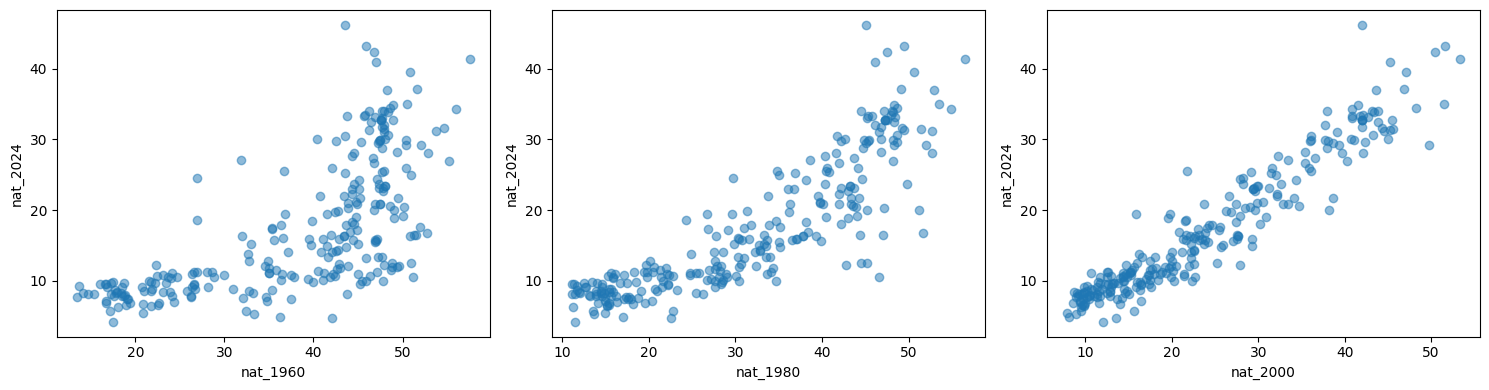

,nat_1960,nat_1980,nat_2000,nat_2024
nat_1960,1.00,0.89,0.75,0.68
nat_1980,0.89,1.00,0.92,0.86
nat_2000,0.75,0.92,1.00,0.95
nat_2024,0.68,0.86,0.95,1.00


In [9]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(ejes, ["nat_1960", "nat_1980", "nat_2000"]):
    ax.scatter(datos[col], datos["nat_2024"], alpha=0.5)
    ax.set_xlabel(col)
    ax.set_ylabel("nat_2024")
plt.tight_layout()
plt.show()

# Correlación: va de -1 a 1. Cuanto más cerca de 1, más relacionadas están las variables
datos.drop(columns="pais").corr().round(2)

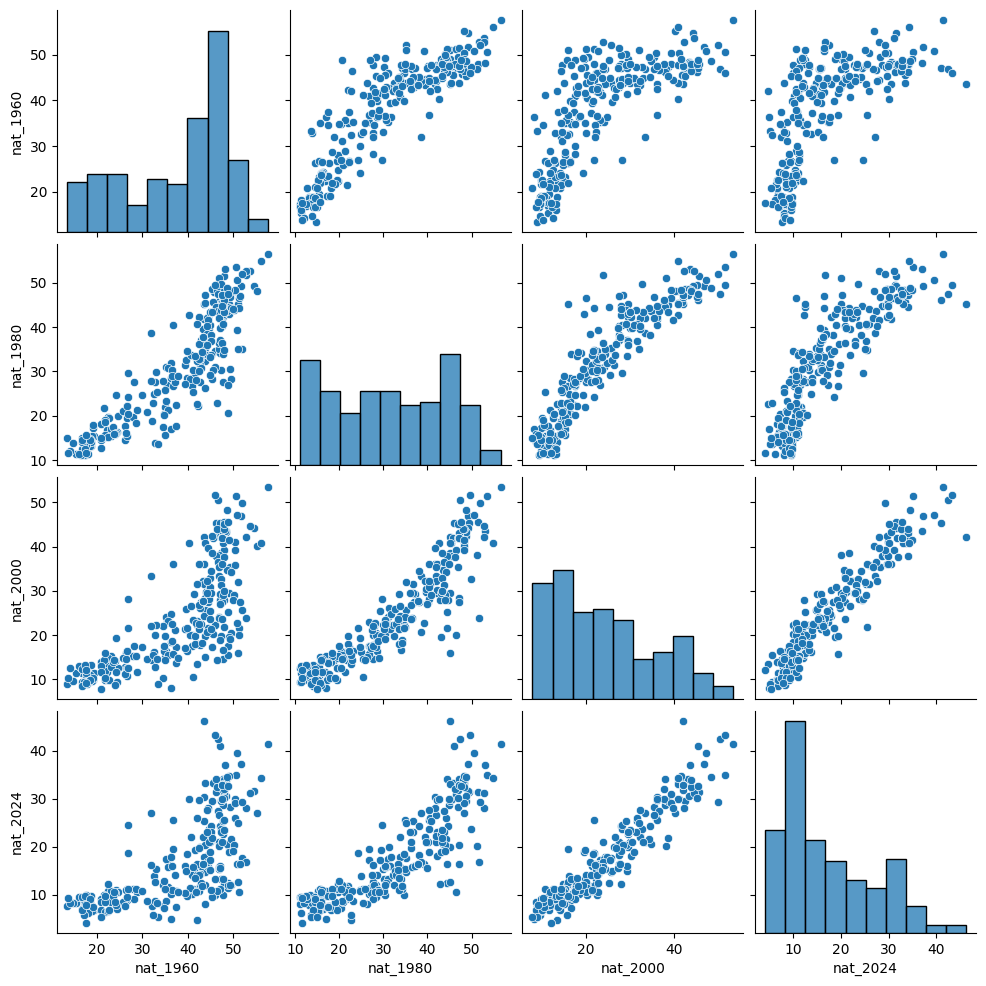

In [10]:
sns.pairplot(datos[["nat_1960", "nat_1980", "nat_2000", "nat_2024"]])
plt.show()

<Axes: >

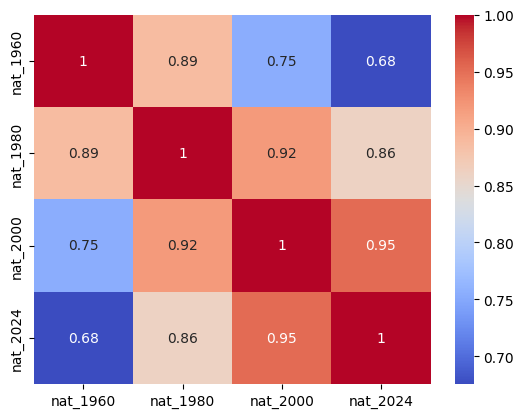

In [11]:
sns.heatmap(datos.drop(columns="pais").corr(), annot=True, cmap="coolwarm")

In [12]:
# Cambio a numpy
X = datos[["nat_1960", "nat_1980", "nat_2000"]].values
y = datos["nat_2024"].values

print("Forma de X:", X.shape, "(filas, columnas)")
print("Forma de y:", y.shape)

Forma de X: (262, 3) (filas, columnas)
Forma de y: (262,)


In [13]:
# Particion de datos (split data / hold out)
# X_train (80%) X_test(20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('X_train', X_train.size)
print('X_test', X_test.size)
print('y_train', y_train.size)
print('y_test', y_test.size)

print("Filas de entrenamiento:", len(X_train))
print("Filas de test:", len(X_test))

X_train 627
X_test 159
y_train 209
y_test 53
Filas de entrenamiento: 209
Filas de test: 53


In [14]:
# Creación del modelo (hipotesis) y ajuste ---> ENTRENMIENTO : Aprendizaje de datos

# Creamos un objeto de la clase LinearRegression
modelo = LinearRegression()

# Entrenamos el modelo pasandole las variables independientes y dependiente
modelo.fit(X_train, y_train)      # "fit" = entrenar el modelo

# Obtención del modelo

# Obtenemos los coheficientes
print("Intercepto (b0):", round(modelo.intercept_, 3))

coeficientes = pd.DataFrame({
    "Variable": ["nat_1960", "nat_1980", "nat_2000"],
    "Coeficiente": modelo.coef_.round(3)
})
coeficientes

Intercepto (b0): 0.539


,Variable,Coeficiente
0,nat_1960,-0.119
1,nat_1980,0.061
2,nat_2000,0.807


In [15]:
# Evaluacion del modelo con los datos de entrenamiento
pred_train = modelo.predict(X_train)

r2_train = r2_score(y_train, pred_train)
mae_train = mean_absolute_error(y_train, pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))

print("R²  :", round(r2_train, 3))
print("MAE :", round(mae_train, 3))
print("RMSE:", round(rmse_train, 3))

R²  : 0.917
MAE : 1.987
RMSE: 2.672


In [16]:
# Obtenemos las predicciones del modelo con los datos de entrenamiento
pred_test = modelo.predict(X_test)

r2_test = r2_score(y_test, pred_test)
mae_test = mean_absolute_error(y_test, pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print("R²  :", round(r2_test, 3))
print("MAE :", round(mae_test, 3))
print("RMSE:", round(rmse_test, 3))

R²  : 0.895
MAE : 2.217
RMSE: 3.204


In [17]:
# comparacion de ambas evaluaciones
comparacion = pd.DataFrame({
    "Métrica": ["R²", "MAE", "RMSE"],
    "Entrenamiento": [r2_train, mae_train, rmse_train],
    "Test": [r2_test, mae_test, rmse_test]
}).round(3)
comparacion

,Métrica,Entrenamiento,Test
0,R²,0.917,0.895
1,MAE,1.987,2.217
2,RMSE,2.672,3.204


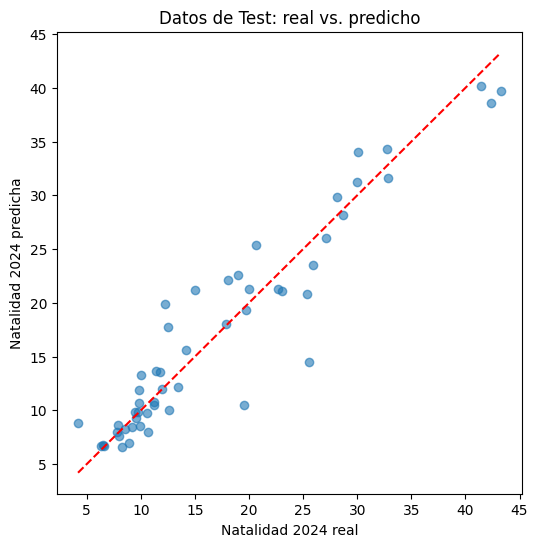

In [18]:
# Valores reales vs valores predichos
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Natalidad 2024 real")
plt.ylabel("Natalidad 2024 predicha")
plt.title("Datos de Test: real vs. predicho")
plt.show()